(7043, 21)


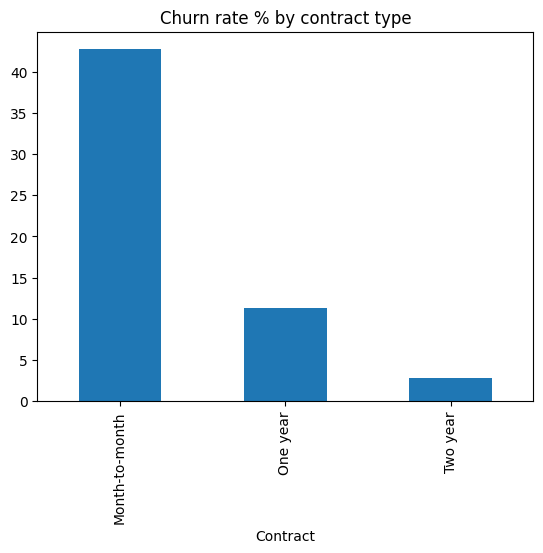

In [1]:
!pip install shap -q
import pandas as pd, shap, xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
raw = pd.read_csv(url)
print(raw.shape)

# Insight 1: churn rate by contract type
(raw.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    .plot(kind="bar", title="Churn rate % by contract type"))
plt.show()

In [2]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna().drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)

X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=int)
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

model = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss")
model.fit(X_train, y_train)

prob = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))
print(classification_report(y_test, model.predict(X_test)))

ROC-AUC: 0.834
              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.49      0.78      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



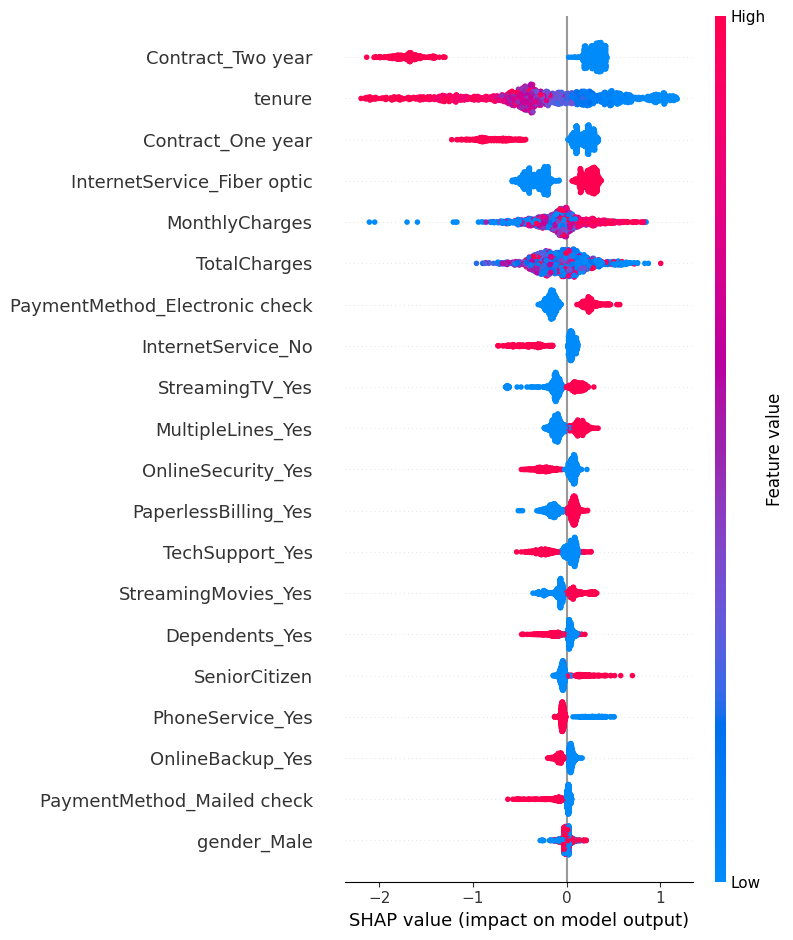

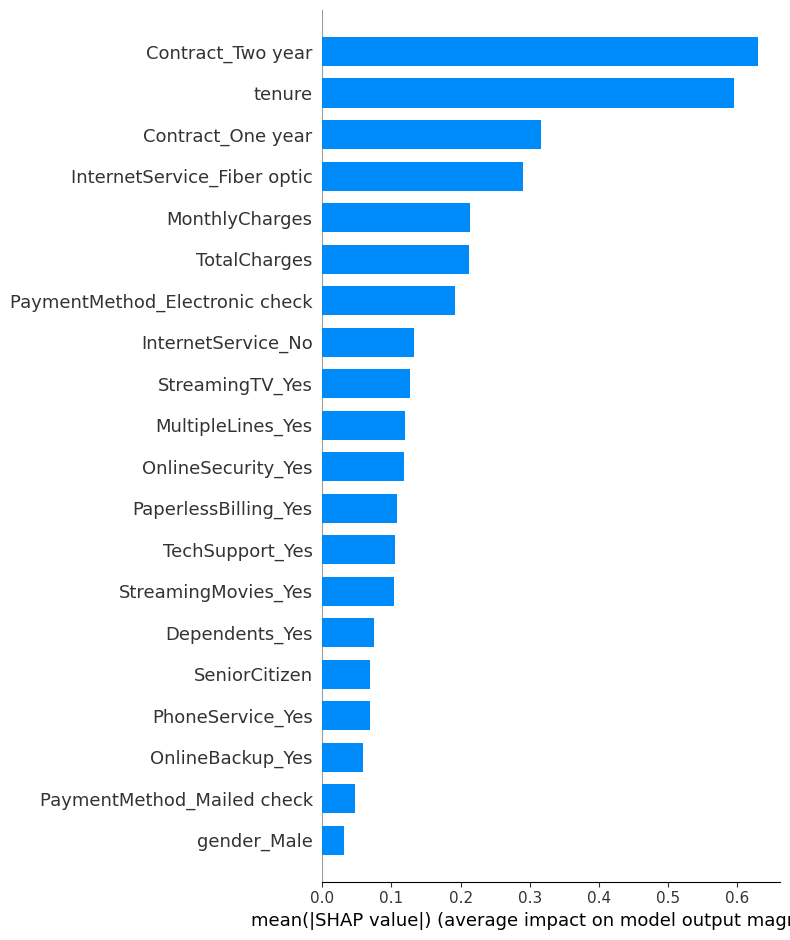

In [3]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)               # top drivers
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [4]:
risk = raw.loc[X_test.index, ["customerID", "Contract", "tenure", "MonthlyCharges"]].copy()
risk["churn_probability"] = prob.round(3)
risk = risk.sort_values("churn_probability", ascending=False)
risk.head(100).to_csv("high_risk_customers.csv", index=False)
print(risk.head(10))

from google.colab import files
files.download("high_risk_customers.csv")

      customerID        Contract  tenure  MonthlyCharges  churn_probability
1731  8375-DKEBR  Month-to-month       1           69.60              0.970
2900  0679-IDSTG  Month-to-month       1           69.25              0.968
4585  1069-XAIEM  Month-to-month       1           85.05              0.968
3380  5178-LMXOP  Month-to-month       1           95.10              0.968
2631  6861-XWTWQ  Month-to-month       7           99.25              0.962
3682  3716-BDVDB  Month-to-month       1           69.10              0.958
809   1820-TQVEV  Month-to-month       1           69.55              0.958
2797  6023-YEBUP  Month-to-month       3          100.95              0.956
3727  9057-SIHCH  Month-to-month       3           96.60              0.953
2464  2609-IAICY  Month-to-month       1           77.15              0.951


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>